In [ ]:
!pip install -q diffusers transformers accelerate safetensors
!pip uninstall -y torchao

In [ ]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

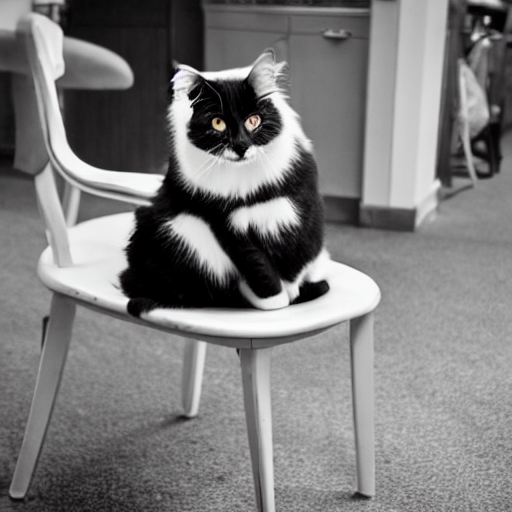

In [ ]:
prompt = "A black and white cat sitting on top of a chair."

generator = torch.Generator(device="cuda").manual_seed(45)

image = pipe(
    prompt,
    generator=generator,
    num_inference_steps=25
).images[0]

display(image)

In [ ]:
import os

os.makedirs("generated_images", exist_ok=True)

image.save("generated_images/p04.png")

In [5]:
import pandas as pd

prompts = pd.read_csv("baseline_prompts.csv")

for _, row in prompts.iterrows():
    generator = torch.Generator(device="cuda").manual_seed(int(row["seed"]))

    image = pipe(
        row["prompt"],
        generator=generator,
        num_inference_steps=25
    ).images[0]

    image.save(f"generated_images/{row['prompt_id']}.png")

    print(f"Finished {row['prompt_id']}")

  0%|          | 0/25 [00:00<?, ?it/s]

Finished p01


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p02


  0%|          | 0/25 [00:00<?, ?it/s]

...

Finished p14


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p15


  0%|          | 0/25 [00:00<?, ?it/s]

Finished p16


In [6]:
import shutil
from google.colab import files

shutil.make_archive("generated_images", "zip", "generated_images")
files.download("generated_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

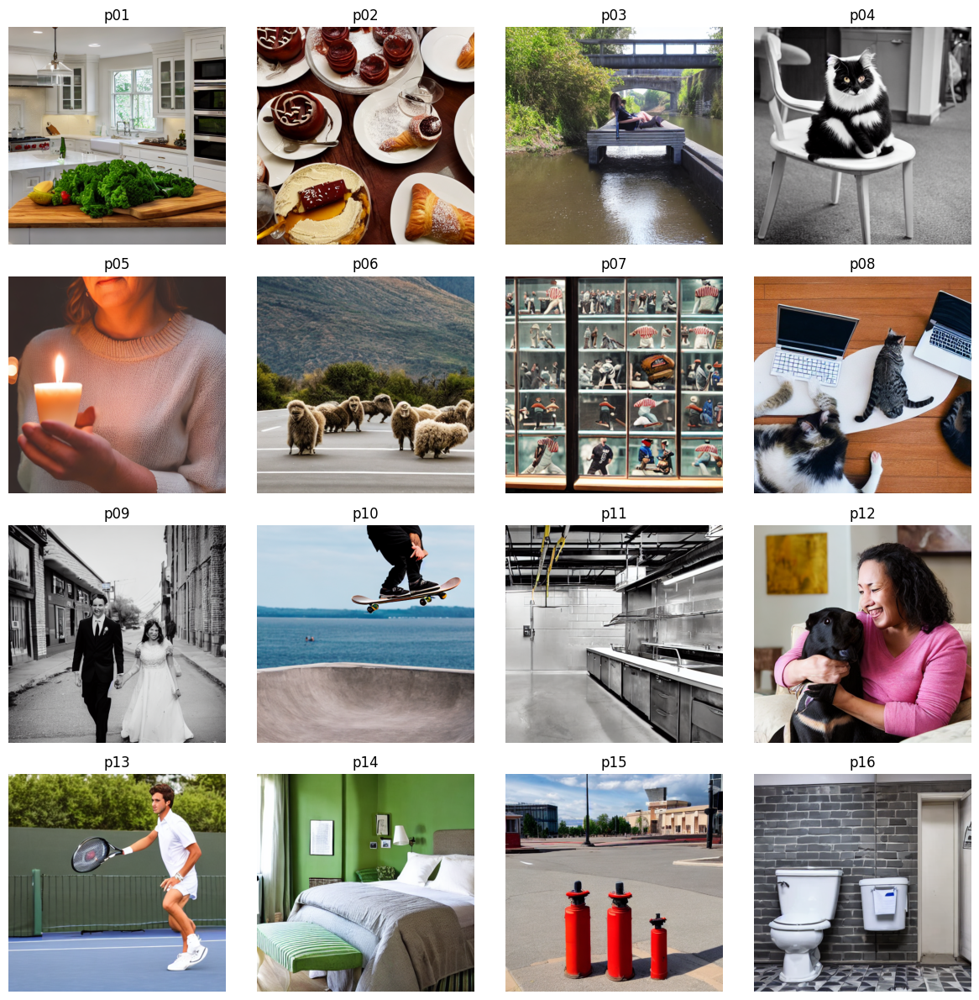

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for ax, (_, row) in zip(axes.flat, prompts.iterrows()):
    image = Image.open(f"generated_images/{row['prompt_id']}.png")

    ax.imshow(image)
    ax.set_title(row["prompt_id"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
manifest = pd.read_csv("manifest.csv")

originals = prompts.merge(
    manifest[["pair_id", "source_url"]],
    on="pair_id",
    how="left"
)

display(originals[["prompt_id", "source_url"]])

,prompt_id,source_url
0,p01,http://farm7.staticflickr.com/6160/6206762667_...
1,p02,http://farm4.staticflickr.com/3040/2791132570_...
2,p03,http://farm6.staticflickr.com/5454/9413846304_...
3,p04,http://farm3.staticflickr.com/2324/2242089027_...
4,p05,http://farm3.staticflickr.com/2062/2243132921_...
5,p06,http://farm3.staticflickr.com/2081/5751829875_...
6,p07,http://farm3.staticflickr.com/2740/5763708656_...
7,p08,http://farm5.staticflickr.com/4038/4212612461_...
8,p09,http://farm3.staticflickr.com/2795/5715794037_...
9,p10,http://farm4.staticflickr.com/3447/3880630600_...


In [12]:
os.makedirs("original_images", exist_ok=True)

for _, row in originals.iterrows():
    image_id = row["pair_id"].split("_")[-1]
    url = f"http://images.cocodataset.org/val2017/{image_id}.jpg"

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content)).convert("RGB")
    image.save(f"original_images/{row['prompt_id']}.png")

    print(f"Downloaded {row['prompt_id']}")

Downloaded p01
Downloaded p02
Downloaded p03
Downloaded p04
Downloaded p05
Downloaded p06
Downloaded p07
Downloaded p08
Downloaded p09
Downloaded p10
Downloaded p11
Downloaded p12
Downloaded p13
Downloaded p14
Downloaded p15
Downloaded p16


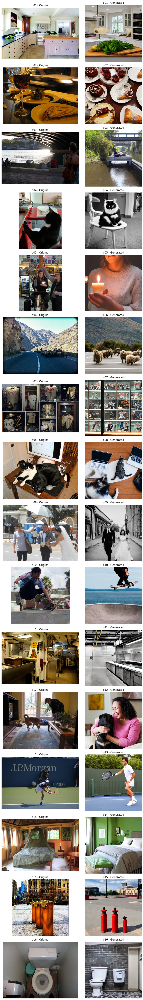

In [15]:
fig, axes = plt.subplots(16, 2, figsize=(10, 64))

for i, (_, row) in enumerate(prompts.iterrows()):
    prompt_id = row["prompt_id"]

    original = Image.open(f"original_images/{prompt_id}.png")
    generated = Image.open(f"generated_images/{prompt_id}.png")

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"{prompt_id} - Original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(generated)
    axes[i, 1].set_title(f"{prompt_id} - Generated")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig("baseline_comparisons.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
files.download("baseline_comparisons.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>